1.Write a Python program to plot a few activation functions that are being used in neural networks.

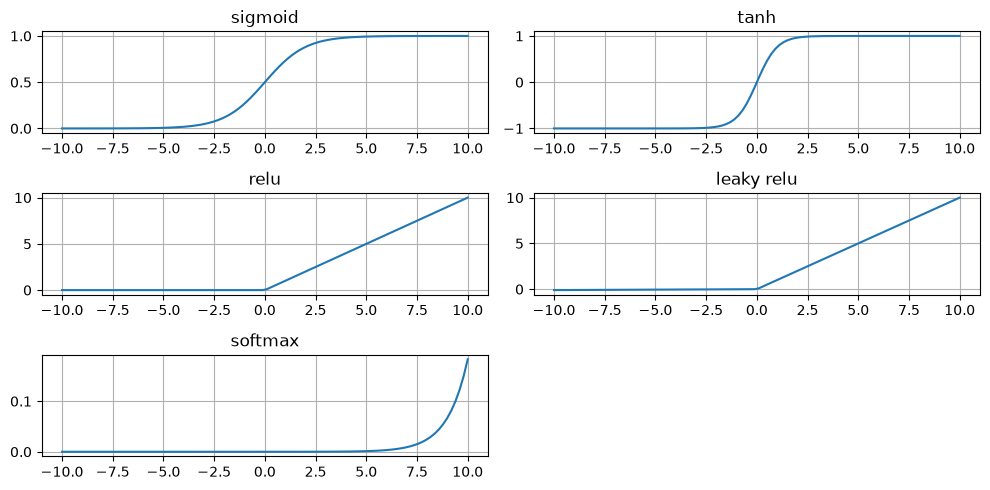

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1/(1+np.exp(-x))

def tanh(x):
    return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))

def relu(x):
  return np.maximum(0,x)

def leaky_relu(x):
  return np.maximum(0.01*x,x)

def softmax(x):
  return np.exp(x)/np.sum(np.exp(x))

x=np.linspace(-10,10,100)

plt.figure(figsize=(10,5))

plt.subplot(3,2,1)
plt.plot(x,sigmoid(x))
plt.title("sigmoid")
plt.grid(True)

plt.subplot(3,2,2)
plt.plot(x,tanh(x))
plt.title("tanh")
plt.grid(True)

plt.subplot(3,2,3)
plt.plot(x,relu(x))
plt.title("relu")
plt.grid(True)

plt.subplot(3,2,4)
plt.plot(x,leaky_relu(x))
plt.title("leaky relu")
plt.grid(True)

plt.subplot(3,2,5)
plt.plot(x,softmax(x))
plt.title("softmax")
plt.grid(True)

plt.tight_layout()
plt.show()

2.Generate AND/OR function using McCulloch-Pitts neural net by a python program

In [2]:
def mc_neuron(inputs, weights, threshold):
    weighted_sum = 0

    for i in range(len(inputs)):
        weighted_sum += inputs[i] * weights[i]

    if weighted_sum >= threshold:
        output = 1
    else:
        output = 0

    return weighted_sum, output


inputs = [
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
]

print("AND Gate")
print("X1 X2 Net Output")

for x in inputs:
    weighted_sum, output = mc_neuron(x, [1, 1], 2)
    print(x[0], x[1], " ", weighted_sum, "   ", output)

AND Gate
X1 X2 Net Output
0 0   0     0
0 1   1     0
1 0   1     0
1 1   2     1


In [3]:
def mp_neuron(inputs,weights,threshold):
    weighted_sum=0

    for i in range(len(inputs)):
        weighted_sum+=inputs[i]*weights[i]
        
    if weighted_sum>=threshold:
        output=1
    else:
        output=0

        return weighted_sum,output
inputs=[
    [0,0],
    [0,1],
    [1,0],
    [1,1]
]
print("\nOR Gate")
print("X1  X2  Net  Output")

for x in inputs:
    net, output = mc_neuron(x, [1, 1], 1)
    print(x[0], " ", x[1], " ", net, "   ", output)


OR Gate
X1  X2  Net  Output
0   0   0     0
0   1   1     1
1   0   1     1
1   1   2     1


3.Write a Python Program using Perceptron Neural Network to recognize even and odd numbers. Given numbers
are in ASCII form 0 to 9.

In [6]:
import numpy as np
# Step activation function
def step_function(x):
    if x >= 0:
        return 1
    else:
        return 0
# Initialize weights, bias and learning rate
weight = np.zeros(8)   # 8 weights for 8-bit binary input
bias = 0
LR = 0.1               # Learning rate
# Training the perceptron
for epoch in range(100):
    for i in range(10):
        # Convert digit into ASCII value
        ascii_value = ord(str(i))
        # Convert ASCII value into 8-bit binary
        binary = format(ascii_value, '08b')
        # Assign label: 0 for even, 1 for odd
        label = 0 if i % 2 == 0 else 1
        # Convert binary string into NumPy array
        inputs = np.array([int(bit) for bit in binary])
        # Calculate weighted sum and predicted output
        outputs = step_function(np.dot(weight, inputs) + bias)
        # Calculate error
        error = label - outputs
        # Update weights
        weight = weight + LR * error * inputs
        # Update bias
        bias = bias + LR * error
# Testing the trained perceptron
digit = input("Enter a digit (0-9): ")
# Convert input into ASCII value
ascii_value = ord(digit)
# Convert ASCII value into 8-bit binary
binary = format(ascii_value, '08b')
# Convert binary into NumPy array
test_input = np.array([int(bit) for bit in binary])
# Predict using trained weights and bias
prediction = step_function(np.dot(weight, test_input) + bias)
# Display the result
print("ASCII value:", ascii_value)
print("ASCII binary:", binary)
if prediction == 0:
    print(digit, "is an even number.")
else:
    print(digit, "is an odd number.")

Enter a digit (0-9):  9


ASCII value: 57
ASCII binary: 00111001
9 is an odd number.


4.With a suitable example demonstrate the perceptron learning law with its decision regions using python. Give
the output in graphical form

Training converged in 6 epochs

========== OUTPUT ==========
Final Weights: [0.3 0.4]
Final Bias: -0.6000000000000001

AND Gate Predictions:
[0 0] = 0
[0 1] = 0
[1 0] = 0
[1 1] = 1


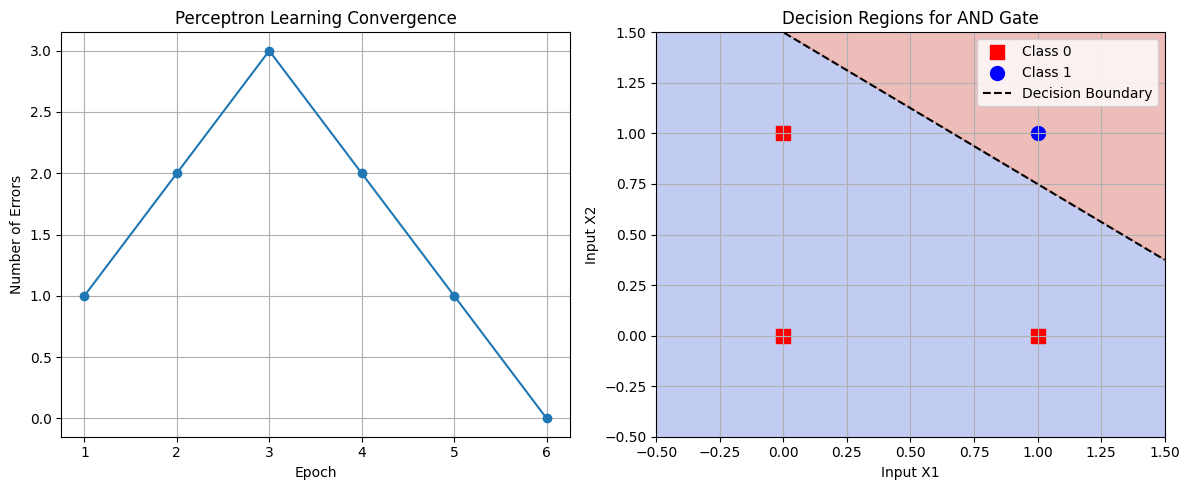

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Dataset (AND Gate)
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

# 2. Initialize parameters
LR = 0.2
max_epochs = 100
weights = np.array([0.3, -0.2])
bias = -0.4
errors = []

# 3. Step function
def step_function(x):
    return 1 if x >= 0 else 0

# 4. Perceptron training
for epoch in range(max_epochs):
    total_error = 0

    for i in range(len(X)):
        net = np.dot(X[i], weights) + bias
        output = step_function(net)

        error = y[i] - output

        weights += LR * error * X[i]
        bias += LR * error

        if error != 0:
            total_error += 1

    errors.append(total_error)

    if total_error == 0:
        print("Training converged in", epoch + 1, "epochs")
        break

# 5. Display results
print("\n========== OUTPUT ==========")
print("Final Weights:", weights)
print("Final Bias:", bias)

print("\nAND Gate Predictions:")
for i in range(len(X)):
    net = np.dot(X[i], weights) + bias
    output = step_function(net)
    print(X[i], "=", output)

# 6. Create decision regions
x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = np.dot(grid, weights) + bias
Z = (Z > 0).astype(int)
Z = Z.reshape(xx.shape)

# 7. Plot graphs
plt.figure(figsize=(12, 5))

# Graph 1: Convergence
plt.subplot(1, 2, 1)

epochs = np.arange(1, len(errors) + 1)

plt.plot(epochs, errors, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Number of Errors")
plt.title("Perceptron Learning Convergence")
plt.xticks(epochs)
plt.grid(True)

# Graph 2: Decision Regions
plt.subplot(1, 2, 2)

plt.contourf(
    xx, yy, Z,
    alpha=0.35,
    cmap="coolwarm"
)

plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    color="red", marker="s",
    s=100, label="Class 0"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", marker="o",
    s=100, label="Class 1"
)

# Decision boundary
x1 = np.linspace(x_min, x_max, 100)

if weights[1] != 0:
    x2 = -(weights[0] * x1 + bias) / weights[1]
    plt.plot(x1, x2, 'k--', label="Decision Boundary")

plt.xlabel("Input X1")
plt.ylabel("Input X2")
plt.title("Decision Regions for AND Gate")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

5.Write a python Program for Bidirectional Associative Memory with two pairs of vectors.

In [5]:
import numpy as np

# Training patterns
x1 = np.array([1, 1, -1, -1])
y1 = np.array([1, 1, 1])

x2 = np.array([1, -1, 1, -1])
y2 = np.array([1, -1, 1])

# Weight matrix
W = np.outer(x1, y1) + np.outer(x2, y2)

print("Weight Matrix:")
print(W)

# Activation function
def activation(x):
    return np.where(x >= 0, 1, -1)
# Forward propagation
def forward(x):
    return activation(np.dot(x, W))

# Backward propagation
def backward(y):
    return activation(np.dot(y, W.T))

# Test x1 -> y1
print("\nFor x1:")
print("Input x1:", x1)
print("Output:", forward(x1))
print("Expected y1:", y1)

# Test x2 -> y2
print("\nFor x2:")
print("Input x2:", x2)
print("Output:", forward(x2))
print("Expected y2:", y2)

# Test y1 -> x1
print("\nFor y1:")
print("Input y1:", y1)
print("Output:", backward(y1))
print("Expected x1:", x1)

# Test y2 -> x2
print("\nFor y2:")
print("Input y2:", y2)
print("Output:", backward(y2))
print("Expected x2:", x2)

# Check recall
print("\nRecall Check:")
print("x1 -> y1:", np.array_equal(forward(x1), y1))
print("x2 -> y2:", np.array_equal(forward(x2), y2))
print("y1 -> x1:", np.array_equal(backward(y1), x1))
print("y2 -> x2:", np.array_equal(backward(y2), x2))

Weight Matrix:
[[ 2  0  2]
 [ 0  2  0]
 [ 0 -2  0]
 [-2  0 -2]]

For x1:
Input x1: [ 1  1 -1 -1]
Output: [1 1 1]
Expected y1: [1 1 1]

For x2:
Input x2: [ 1 -1  1 -1]
Output: [ 1 -1  1]
Expected y2: [ 1 -1  1]

For y1:
Input y1: [1 1 1]
Output: [ 1  1 -1 -1]
Expected x1: [ 1  1 -1 -1]

For y2:
Input y2: [ 1 -1  1]
Output: [ 1 -1  1 -1]
Expected x2: [ 1 -1  1 -1]

Recall Check:
x1 -> y1: True
x2 -> y2: True
y1 -> x1: True
y2 -> x2: True


In [6]:
def activation(x):
    return np.where(x>=0,1,-1)

6.Write a python program to recognize the number 0, 1, 2, 3, 9. A 5 * 3 matrix forms the numbers. For any valid
point it is taken as 1 and invalid point it is taken as 0. The net has to be trained to recognize all the numbers and
when the test data is given, the network has to recognize the particular numbers.

In [7]:
import numpy as np

# Training patterns for digits 0 to 9
patterns = {
    0: [[1,1,1],
        [1,0,1],
        [1,0,1],
        [1,0,1],
        [1,1,1]],

    1: [[0,1,0],
        [1,1,0],
        [0,1,0],
        [0,1,0],
        [1,1,1]],

    2: [[1,1,1],
        [0,0,1],
        [1,1,1],
        [1,0,0],
        [1,1,1]],

    3: [[1,1,1],
        [0,0,1],
        [1,1,1],
        [0,0,1],
        [1,1,1]],

    4: [[1,0,1],
        [1,0,1],
        [1,1,1],
        [0,0,1],
        [0,0,1]],

    5: [[1,1,1],
        [1,0,0],
        [1,1,1],
        [0,0,1],
        [1,1,1]],

    6: [[1,1,1],
        [1,0,0],
        [1,1,1],
        [1,0,1],
        [1,1,1]],

    7: [[1,1,1],
        [0,0,1],
        [0,1,0],
        [0,1,0],
        [0,1,0]],

    8: [[1,1,1],
        [1,0,1],
        [1,1,1],
        [1,0,1],
        [1,1,1]],

    9: [[1,1,1],
        [1,0,1],
        [1,1,1],
        [0,0,1],
        [1,1,1]]
}

# Prepare training data
digits = list(patterns.keys())
X = np.array([np.array(patterns[d]).flatten() for d in digits])
T = np.eye(10)

# Initialize weights and bias
weights = np.zeros((10, 15))
bias = np.zeros(10)

# Training
for epoch in range(100):
    for i in range(10):
        net = np.dot(weights, X[i]) + bias
        output = np.zeros(10)
        output[np.argmax(net)] = 1
        error = T[i] - output

        weights += 0.1 * np.outer(error, X[i])
        bias += 0.1 * error

# Test the network
n = int(input("Enter digit to recognize (0-9): "))

if n in patterns:
    test = np.array(patterns[n]).flatten()
    net = np.dot(weights, test) + bias

    print("\nInput Matrix:")
    print(np.array(patterns[n]))
    print("\nRecognized Digit:", digits[np.argmax(net)])
else:
    print("Invalid digit!")

Enter digit to recognize (0-9):  9



Input Matrix:
[[1 1 1]
 [1 0 1]
 [1 1 1]
 [0 0 1]
 [1 1 1]]

Recognized Digit: 9


7.Implement Artificial Neural Network training process in Python by using Forward Propagation, Back
Propagation: Handwritten Digit Recognition (MNIST Dataset)-Implement a 3-layer neural network (Input
→Hidden → Output) using Backpropagation.
a. Use Sigmoid, ReLU, or Tanh activation functions.
b. Train the network on the MNIST dataset to classify handwritten digits (0-9).
c. Optimize using Gradient Descent with Momentum or Adam Optimize

In [8]:
pip install keras

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [9]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [1]:
import keras
import tensorflow as tf

Training data shape: (60000, 785)
Testing data shape: (10000, 785)


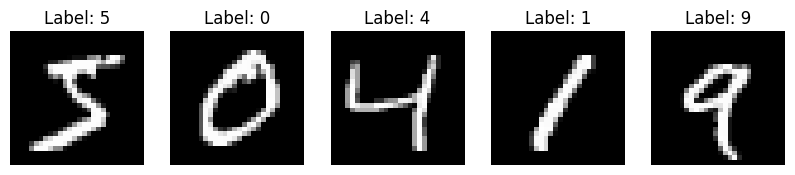

C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9173 - loss: 0.2921 - val_accuracy: 0.9549 - val_loss: 0.1586
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9626 - loss: 0.1297 - val_accuracy: 0.9662 - val_loss: 0.1167
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9743 - loss: 0.0885 - val_accuracy: 0.9707 - val_loss: 0.0982
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9801 - loss: 0.0657 - val_accuracy: 0.9738 - val_loss: 0.0886
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9850 - loss: 0.0506 - val_accuracy: 0.9772 - val_loss: 0.0809
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9879 - loss: 0.0392 - val_accuracy: 0.9739 - val_loss: 0.0852
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9900 - loss: 0.0333 - val_accuracy: 0.9758 - val_loss: 0.0835
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9929 - loss: 0.0248 - 

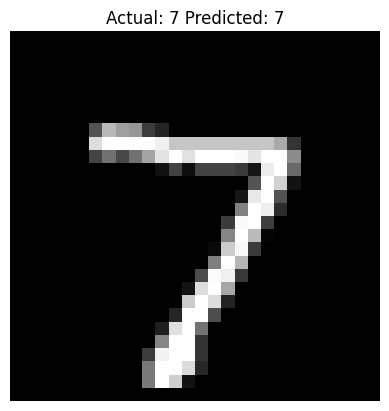

Image: 2 Actual: 2 Predicted: 2


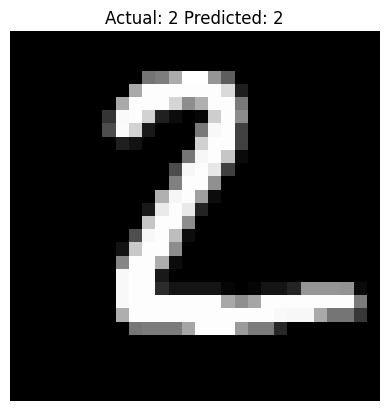

Image: 3 Actual: 1 Predicted: 1


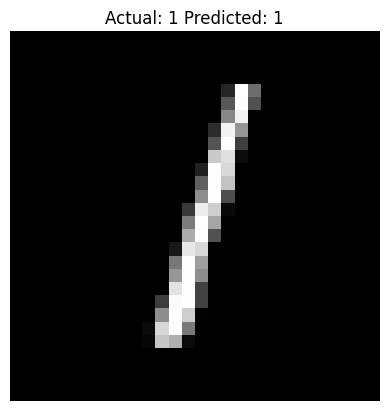

Image: 4 Actual: 0 Predicted: 0


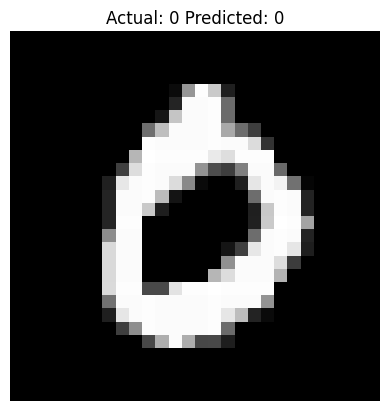

Image: 5 Actual: 4 Predicted: 4


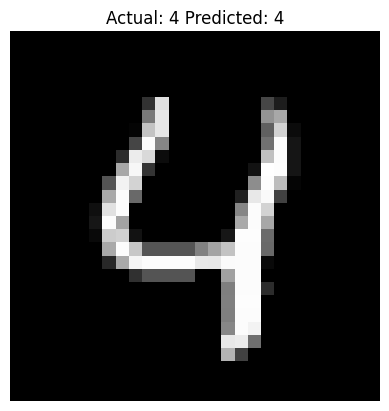

Image: 6 Actual: 1 Predicted: 1


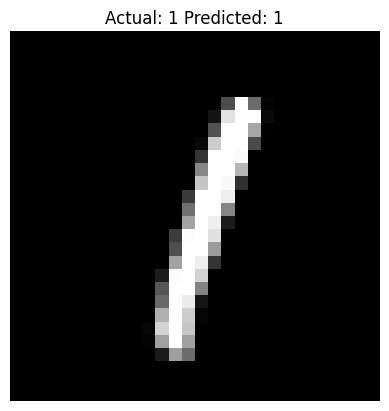

Image: 7 Actual: 4 Predicted: 4


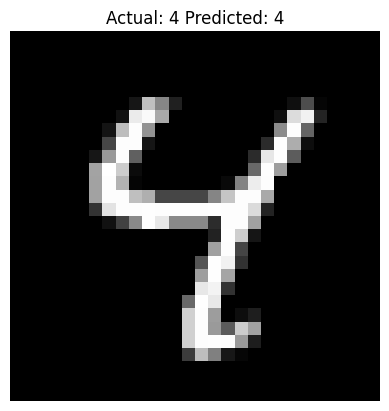

Image: 8 Actual: 9 Predicted: 9


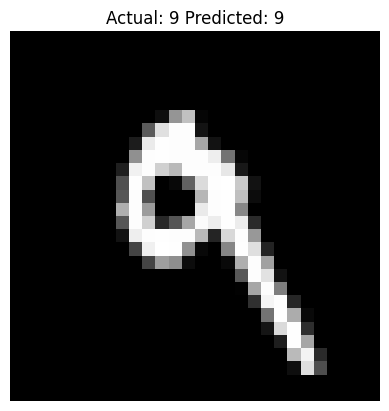

Image: 9 Actual: 5 Predicted: 6


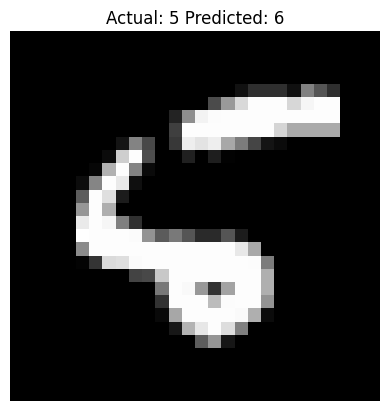

Image: 10 Actual: 9 Predicted: 9


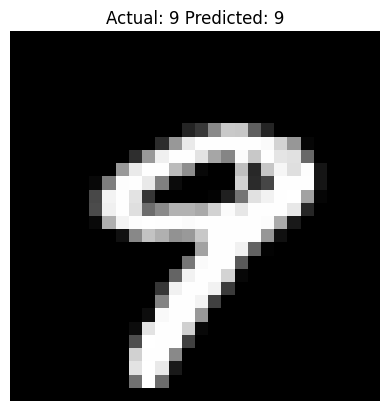

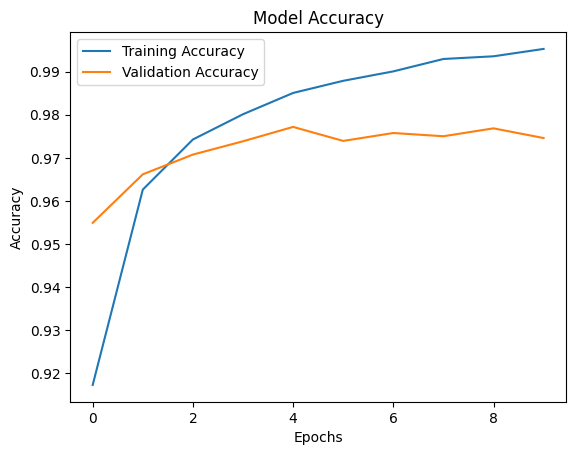

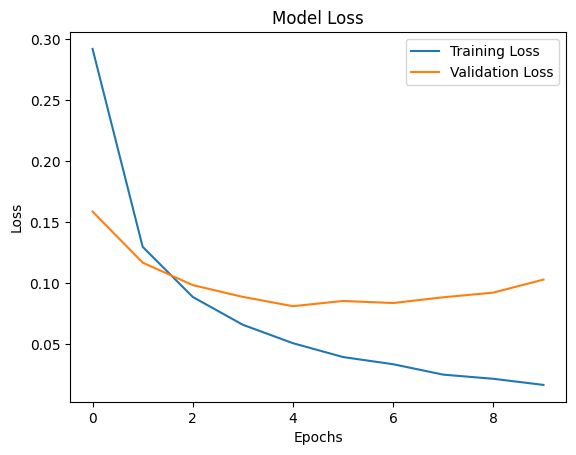

In [2]:

# 1. Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


# 2. Load training and testing CSV files

train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)


# 3. Separate features and labels

x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values


# 4. Normalize pixel values

x_train = x_train / 255.0
x_test = x_test / 255.0


# 5. Display sample images

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')

plt.show()


# 6. Build a 3-layer Neural Network

model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

model.summary()


# 7. Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# 8. Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)


# 9. Evaluate the model

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


# 10. Predict handwritten digits

predictions = model.predict(x_test)

for i in range(10):

    predicted = np.argmax(predictions[i])

    print("Image:", i+1,
          "Actual:", y_test[i],
          "Predicted:", predicted)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Actual: " + str(y_test[i]) +
              " Predicted: " + str(predicted))
    plt.axis('off')
    plt.show()


# 11. Plot training and validation accuracy

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# 12. Plot training and validation loss

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


8.Create a Neural network architecture from scratch in Python and use it to do multi-class classification on any
data. Parameters to be considered while creating the neural network from scratch are specified as: (1) No of
hidden layers : 1 or more (2) No. of neurons in hidden layer: 100 (3) Non-linearity in the layer : Relu (4) Use
more than 1 neuron in the output layer. Use a suitable threshold value Use appropriate Optimization algorithm

Dataset Shape: (150, 4)
Number of Classes: 3
Epoch: 100 Loss: 0.3214
Epoch: 200 Loss: 0.2718
Epoch: 300 Loss: 0.2448
Epoch: 400 Loss: 0.226
Epoch: 500 Loss: 0.2114
Epoch: 600 Loss: 0.1992
Epoch: 700 Loss: 0.1888
Epoch: 800 Loss: 0.1796
Epoch: 900 Loss: 0.1714
Epoch: 1000 Loss: 0.1639

Neural Network Results
Hidden Neurons : 100
Activation     : ReLU
Output Neurons : 3
Output Function: Softmax
Optimizer      : Gradient Descent
Learning Rate  : 0.01
Epochs         : 1000

Actual Classes:    [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Classes: [0 2 1 1 0 2 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]
Test Accuracy: 90.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  8  2]
 [ 0  1  9]]


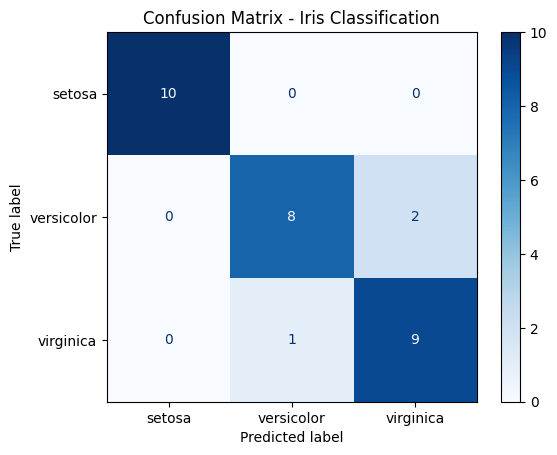


Sample Predictions:
-----------------------------------
Actual: 0  Predicted: 0  Probabilities: [0.999 0.001 0.   ]
Actual: 2  Predicted: 2  Probabilities: [0.002 0.098 0.9  ]
Actual: 1  Predicted: 1  Probabilities: [0.039 0.942 0.019]
Actual: 1  Predicted: 1  Probabilities: [0.015 0.974 0.011]
Actual: 0  Predicted: 0  Probabilities: [1. 0. 0.]
Actual: 1  Predicted: 2  Probabilities: [0.019 0.425 0.556]
Actual: 0  Predicted: 0  Probabilities: [1. 0. 0.]
Actual: 0  Predicted: 0  Probabilities: [0.996 0.003 0.   ]
Actual: 2  Predicted: 2  Probabilities: [0.    0.037 0.963]
Actual: 1  Predicted: 1  Probabilities: [0.042 0.553 0.405]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Load dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Number of Classes:", len(np.unique(y)))

# Convert labels to one-hot encoding
Y = np.eye(3)[y]

# 2. Split dataset
X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Normalize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Initialize neural network
np.random.seed(42)

# Input layer: 4 features
# Hidden layer: 100 neurons
# Output layer: 3 classes

W1 = np.random.randn(4, 100) * np.sqrt(2 / 4)
b1 = np.zeros((1, 100))

W2 = np.random.randn(100, 3) * 0.01
b2 = np.zeros((1, 3))

learning_rate = 0.01
epochs = 1000

# 5. Activation functions
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# 6. Train the neural network
for epoch in range(epochs):

    # Forward propagation
    Z1 = np.dot(X_train, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    # Calculate cross-entropy loss
    loss = -np.mean(
        np.sum(Y_train * np.log(A2 + 1e-9), axis=1)
    )

    # Backpropagation
    dZ2 = (A2 - Y_train) / len(X_train)

    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivative(Z1)

    dW1 = np.dot(X_train.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Update weights and biases using gradient descent
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    # Display loss after every 200 epochs
    if (epoch + 1) % 100 == 0:
        print("Epoch:", epoch + 1, "Loss:", round(loss, 4))

# 7. Test the neural network
Z1_test = np.dot(X_test, W1) + b1
A1_test = relu(Z1_test)

Z2_test = np.dot(A1_test, W2) + b2
A2_test = softmax(Z2_test)

# Apply threshold
threshold = 0.5
threshold_output = (A2_test >= threshold).astype(int)

# Predict class with the highest probability
predictions = np.argmax(A2_test, axis=1)

# Actual class labels
y_actual = y_test

# 8. Calculate accuracy using accuracy_score
accuracy = accuracy_score(y_actual, predictions) * 100

print("\n===================================")
print("Neural Network Results")
print("===================================")

print("Hidden Neurons :", 100)
print("Activation     : ReLU")
print("Output Neurons :", 3)
print("Output Function: Softmax")
print("Optimizer      : Gradient Descent")
print("Learning Rate  :", learning_rate)
print("Epochs         :", epochs)

print("\nActual Classes:   ", y_actual)
print("Predicted Classes:", predictions)

print("Test Accuracy:", round(accuracy, 2), "%")

# 9. Confusion matrix
cm = confusion_matrix(y_actual, predictions)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Iris Classification")
plt.show()

# 10. Sample predictions
print("\nSample Predictions:")
print("-----------------------------------")

for i in range(min(10, len(X_test))):
    print(
        "Actual:", y_actual[i],
        " Predicted:", predictions[i],
        " Probabilities:", np.round(A2_test[i], 3)
    )


9.Write a python program to illustrate ART neural network: Clustering 2D Data Using ART1-
a. Implement the ART1 algorithm for binary input data.
b. Given a set of binary vectors, cluster them into categories based on similarity.
c. Use vigilance parameter (ρ) to control cluster formation. Clustering 2D Data using Winner-Takes-All (WTA)
Network Implement a Winner-Takes-All (WTA) neural network to cluster 2D data points.
d. Each neuron represents a cluster center, and only the winning neuron (closest to input) updates its weights.
e. Train the network on randomly generated 2D points and visualize the clusters.

ART1 Clustering
[1 1 1 0 0 0] -> Cluster 1
[1 1 0 0 0 0] -> Cluster 1
[1 1 1 0 0 0] -> Cluster 2
[0 0 0 1 1 1] -> Cluster 3
[0 0 0 1 1 0] -> Cluster 3
[0 0 0 1 1 1] -> Cluster 4
Number of clusters: 4

WTA Cluster Centers:
[[1.9051624  1.95777959]
 [5.23486173 6.92941528]
 [6.93905017 3.34671587]]


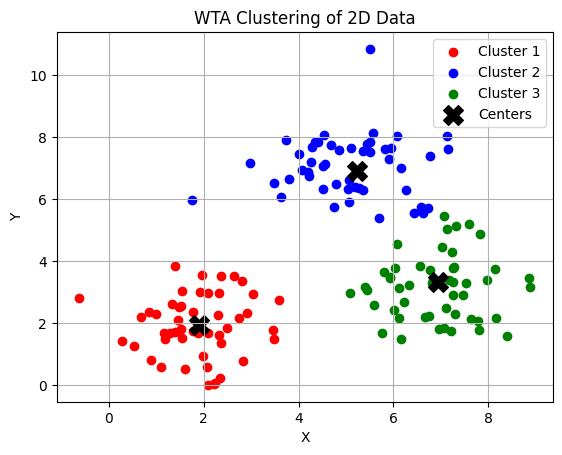

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# ART1 - Clustering Binary Data
# =========================================================

data = np.array([
    [1, 1, 1, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
    [1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 0],
    [0, 0, 0, 1, 1, 1]
])

rho = 0.7                 # Vigilance parameter
weights = []              # Cluster prototypes
clusters = []

for x in data:

    found = False

    # Check existing clusters
    for i in range(len(weights)):

        w = weights[i]

        # Similarity / match
        similarity = np.sum(x * w) / np.sum(x)

        if similarity >= rho:
            # ART1 learning
            weights[i] = x * w
            clusters.append(i)
            found = True
            break

    # Create a new cluster
    if not found:
        weights.append(x.copy())
        clusters.append(len(weights) - 1)


print("ART1 Clustering")
for i in range(len(data)):
    print(data[i], "-> Cluster", clusters[i] + 1)

print("Number of clusters:", len(weights))


# =========================================================
# WTA - Clustering 2D Data
# =========================================================

np.random.seed(42)

# Generate 2D data
data2 = np.vstack([
    np.random.randn(50, 2) + [2, 2],
    np.random.randn(50, 2) + [7, 3],
    np.random.randn(50, 2) + [5, 7]
])

# Number of clusters
k = 3

# Random cluster centers
centers = np.random.rand(k, 2) * 10

learning_rate = 0.1

# Training
for epoch in range(20):

    for x in data2:

        # Find distance from x to every center
        distances = np.linalg.norm(centers - x, axis=1)

        # Winner = closest center
        winner = np.argmin(distances)

        # Update only winner
        centers[winner] = centers[winner] + \
            learning_rate * (x - centers[winner])


# Assign points to clusters
clusters2 = []

for x in data2:

    distances = np.linalg.norm(centers - x, axis=1)
    winner = np.argmin(distances)

    clusters2.append(winner)

clusters2 = np.array(clusters2)


# =========================================================
# Display Results
# =========================================================

print("\nWTA Cluster Centers:")
print(centers)


# Plot clusters
colors = ["red", "blue", "green"]

for i in range(k):
    points = data2[clusters2 == i]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        color=colors[i],
        label="Cluster " + str(i + 1)
    )

# Plot centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color="black",
    marker="X",
    s=200,
    label="Centers"
)

plt.title("WTA Clustering of 2D Data")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid()
plt.show()


10.Implementing Self-Organizing Maps (SOM) for Image Compression-
a. Implement Kohonen’s Self-Organizing Map (SOM) for image compression.

b. Train SOM to reduce the number of colors in an image.
c. Display the original and compressed images to analyze quality loss

SOM Training Completed!


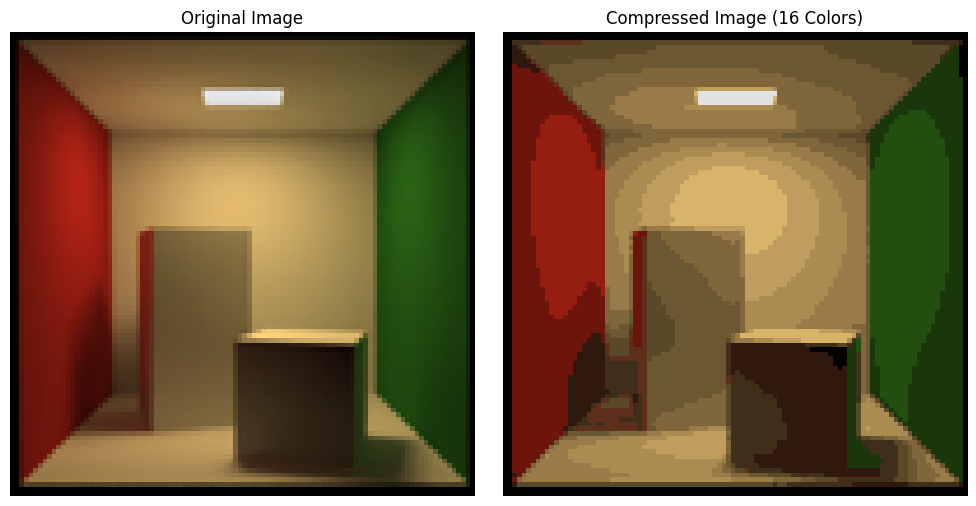


Image Quality Analysis
----------------------
Mean Squared Error (MSE): 45.06216666666667
Peak Signal-to-Noise Ratio (PSNR): 31.592682913505968 dB
Mean Absolute Error (MAE): 4.840566666666667

SOM Image Compression Completed!
Original Image Size: (100, 100)
Number of Colors: 16
Compressed image saved as compressed.jpg


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

np.random.seed(42)

# 1. Load Image
img = Image.open("BOX (1).png").convert("RGB")
img = img.resize((100, 100))

# 2. Convert Image into RGB Pixels
pixels = np.array(img)
pixels = pixels.reshape(-1, 3).astype(float)

# 3. Initialize SOM
k = 16
weights = np.random.rand(k, 3) * 255

learning_rate = 0.5
radius = k / 2
epochs = 50

# 4. Train SOM
for epoch in range(epochs):

    # Shuffle pixels
    shuffled_pixels = pixels.copy()
    np.random.shuffle(shuffled_pixels)

    # Decrease learning rate and radius
    lr = learning_rate * (1 - epoch / epochs)
    r = radius * (1 - epoch / epochs)

    for pixel in shuffled_pixels:

        # Calculate Euclidean distance
        distances = np.linalg.norm(weights - pixel, axis=1)

        # Find Best Matching Unit (BMU)
        bmu = np.argmin(distances)

        # Update BMU and neighboring neurons
        for i in range(k):

            distance = abs(i - bmu)

            if distance <= r:

                influence = np.exp(
                    -(distance ** 2) / (2 * r ** 2 + 1e-10)
                )

                weights[i] += lr * influence * (pixel - weights[i])

print("SOM Training Completed!")

# 5. Compress Image
compressed = []

for pixel in pixels:

    distances = np.linalg.norm(weights - pixel, axis=1)

    bmu = np.argmin(distances)

    compressed.append(weights[bmu])

# Convert into image
compressed = np.array(compressed)
compressed = compressed.reshape(100, 100, 3)

compressed = np.clip(compressed, 0, 255).astype(np.uint8)

# 6. Display Original and Compressed Images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(compressed)
plt.title("Compressed Image (16 Colors)")
plt.axis("off")

plt.tight_layout()
plt.show()

# 7. Calculate Quality Loss
original = np.array(img).astype(float)
compressed_float = compressed.astype(float)

# Mean Squared Error (MSE)
mse = np.mean((original - compressed_float) ** 2)

# Peak Signal-to-Noise Ratio (PSNR)
if mse == 0:
    psnr = float('inf')
else:
    psnr = 10 * np.log10((255 ** 2) / mse)

# Mean Absolute Error (MAE)
mae = np.mean(np.abs(original - compressed_float))

# Display Results
print("\nImage Quality Analysis")
print("----------------------")
print("Mean Squared Error (MSE):", mse)
print("Peak Signal-to-Noise Ratio (PSNR):", psnr, "dB")
print("Mean Absolute Error (MAE):", mae)

# 8. Save Compressed Image
Image.fromarray(compressed).save("compressed.jpg")

print("\nSOM Image Compression Completed!")
print("Original Image Size:", img.size)
print("Number of Colors:", k)
print("Compressed image saved as compressed.jpg")

Object Recognition using CNN (CIFAR-10 Dataset)
a. Train a CNN model to classify CIFAR-10 images into 10 object categories (airplane, cat,
car, dog, etc.).
b. Use data augmentation to improve model generalization.
c. Compare model performance with and without Batch Normalization and Dropout

In [6]:
pip install tensorflow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip
